In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

In [2]:
DATA_PATH = Path("../data/raw/creditcard.csv")

df = pd.read_csv(DATA_PATH)

X = df.drop(columns=["Class"])
y = df["Class"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Treino:", X_train.shape)
print("Validação:", X_val.shape)
print("Teste:", X_test.shape)

Treino: (199364, 30)
Validação: (42721, 30)
Teste: (42722, 30)


In [4]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

print(rf_model)

RandomForestClassifier(class_weight='balanced_subsample', max_depth=12,
                       min_samples_leaf=2, n_jobs=-1, random_state=42)


In [5]:
rf_model.fit(X_train, y_train)

print("Random Forest treinada com sucesso!")

Random Forest treinada com sucesso!


In [6]:
y_pred_rf = rf_model.predict(X_val)

y_proba_rf = rf_model.predict_proba(X_val)[:, 1]

print("Primeiras 10 previsões:")
print(y_pred_rf[:10])

print("\nPrimeiros 10 scores de fraude:")
print(y_proba_rf[:10])

print("\nQuantidade prevista por classe:")
print(pd.Series(y_pred_rf).value_counts())

Primeiras 10 previsões:
[0 0 0 0 0 0 0 0 0 0]

Primeiros 10 scores de fraude:
[0.0041944  0.         0.00041905 0.00295568 0.         0.01254954
 0.00452144 0.001429   0.         0.00058551]

Quantidade prevista por classe:
0    42654
1       67
Name: count, dtype: int64


In [7]:
print("=== RANDOM FOREST ===")

print(classification_report(
    y_val,
    y_pred_rf,
    digits=4,
    zero_division=0
))

pr_auc_rf = average_precision_score(
    y_val,
    y_proba_rf
)

roc_auc_rf = roc_auc_score(
    y_val,
    y_proba_rf
)

print(f"Average Precision: {pr_auc_rf:.4f}")
print(f"ROC-AUC: {roc_auc_rf:.4f}")

print("\nMatriz de confusão:")
print(confusion_matrix(y_val, y_pred_rf))

=== RANDOM FOREST ===
              precision    recall  f1-score   support

           0     0.9996    0.9997    0.9996     42647
           1     0.8209    0.7432    0.7801        74

    accuracy                         0.9993     42721
   macro avg     0.9102    0.8715    0.8899     42721
weighted avg     0.9992    0.9993    0.9993     42721

Average Precision: 0.7988
ROC-AUC: 0.9643

Matriz de confusão:
[[42635    12]
 [   19    55]]


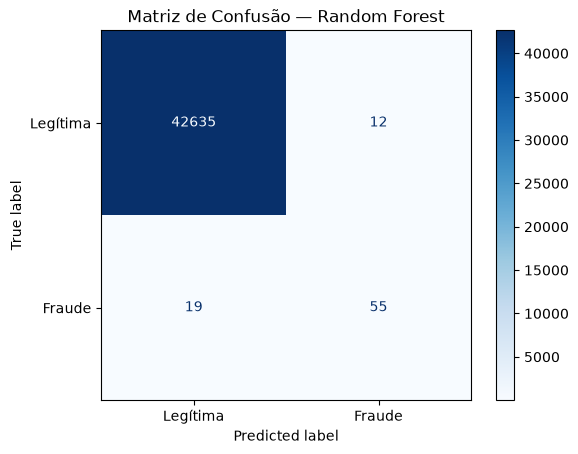

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_rf,
    display_labels=["Legítima", "Fraude"],
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de Confusão — Random Forest")
plt.show()

In [9]:
from xgboost import XGBClassifier

import xgboost

print("Versão do XGBoost:", xgboost.__version__)

Versão do XGBoost: 3.4.1


In [10]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print(f"Peso da classe positiva: {scale_pos_weight:.2f}")

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

print(xgb_model)

Peso da classe positiva: 578.55
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)


In [11]:
xgb_model.fit(X_train, y_train)

print("XGBoost treinado com sucesso!")

XGBoost treinado com sucesso!


In [12]:
y_pred_xgb = xgb_model.predict(X_val)

y_proba_xgb = xgb_model.predict_proba(X_val)[:, 1]

print("Primeiras 10 previsões:")
print(y_pred_xgb[:10])

print("\nPrimeiros 10 scores de fraude:")
print(y_proba_xgb[:10])

print("\nQuantidade prevista por classe:")
print(pd.Series(y_pred_xgb).value_counts())

Primeiras 10 previsões:
[0 0 0 0 0 0 0 0 0 0]

Primeiros 10 scores de fraude:
[1.9582943e-04 2.1250789e-04 1.3578130e-04 2.9102638e-03 8.7951055e-05
 1.0344219e-02 6.4167840e-04 7.1366812e-04 3.6198445e-04 1.6525081e-04]

Quantidade prevista por classe:
0    42628
1       93
Name: count, dtype: int64


In [13]:
print("=== XGBOOST ===")

print(classification_report(
    y_val,
    y_pred_xgb,
    digits=4,
    zero_division=0
))

pr_auc_xgb = average_precision_score(
    y_val,
    y_proba_xgb
)

roc_auc_xgb = roc_auc_score(
    y_val,
    y_proba_xgb
)

print(f"Average Precision: {pr_auc_xgb:.4f}")
print(f"ROC-AUC: {roc_auc_xgb:.4f}")

print("\nMatriz de confusão:")
print(confusion_matrix(y_val, y_pred_xgb))

=== XGBOOST ===
              precision    recall  f1-score   support

           0     0.9997    0.9992    0.9994     42647
           1     0.6452    0.8108    0.7186        74

    accuracy                         0.9989     42721
   macro avg     0.8224    0.9050    0.8590     42721
weighted avg     0.9991    0.9989    0.9990     42721

Average Precision: 0.8198
ROC-AUC: 0.9855

Matriz de confusão:
[[42614    33]
 [   14    60]]


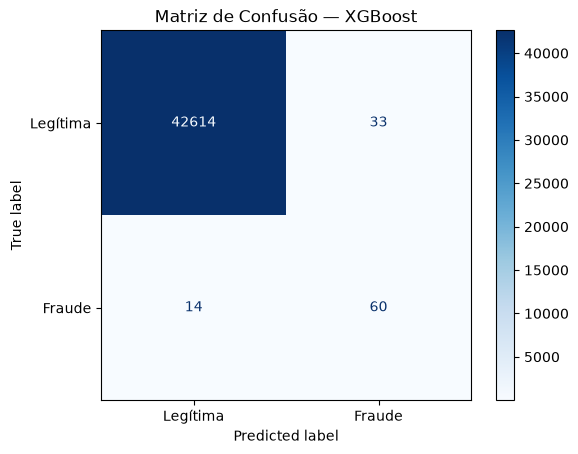

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_xgb,
    display_labels=["Legítima", "Fraude"],
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de Confusão — XGBoost")
plt.show()

In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Random Forest": {
        "pred": y_pred_rf,
        "proba": y_proba_rf
    },
    "XGBoost": {
        "pred": y_pred_xgb,
        "proba": y_proba_xgb
    }
}

results = []

for name, outputs in models.items():
    predictions = outputs["pred"]
    probabilities = outputs["proba"]

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions
    ).ravel()

    results.append({
        "Modelo": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_val, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        ),
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))

,Modelo,Accuracy,Precision,Recall,F1-score,Average Precision,ROC-AUC,FP,FN,TP
0,Random Forest,0.9993,0.8209,0.7432,0.7801,0.7988,0.9643,12,19,55
1,XGBoost,0.9989,0.6452,0.8108,0.7186,0.8198,0.9855,33,14,60


In [16]:
RESULTS_DIR = Path("../artifacts/experiments")

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RESULTS_PATH = RESULTS_DIR / "model_comparison.csv"

comparison_df.to_csv(
    RESULTS_PATH,
    index=False
)

print("Resultados salvos em:", RESULTS_PATH)

Resultados salvos em: ..\artifacts\experiments\model_comparison.csv


In [17]:
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)

In [18]:
param_distributions = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "min_child_weight": [1, 3, 5]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

print("Espaço de busca configurado!")

Espaço de busca configurado!


In [21]:
xgb_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ),
    param_distributions=param_distributions,
    n_iter=10,
    scoring="average_precision",
    cv=cv,
    verbose=1,
    random_state=42,
    n_jobs=-1,
    refit=True
)

print("RandomizedSearchCV configurado!")

RandomizedSearchCV configurado!


In [22]:
xgb_search.fit(X_train, y_train)

print("\nOtimização concluída!")

print("\nMelhores hiperparâmetros:")
print(xgb_search.best_params_)

print("\nMelhor Average Precision na validação cruzada:")
print(round(xgb_search.best_score_, 4))

Fitting 3 folds for each of 10 candidates, totalling 30 fits

Otimização concluída!

Melhores hiperparâmetros:
{'subsample': 1.0, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.8}

Melhor Average Precision na validação cruzada:
0.8465


In [23]:
best_xgb = xgb_search.best_estimator_

y_pred_best_xgb = best_xgb.predict(X_val)
y_proba_best_xgb = best_xgb.predict_proba(X_val)[:, 1]

print("=== XGBOOST OTIMIZADO ===")

print(classification_report(
    y_val,
    y_pred_best_xgb,
    digits=4,
    zero_division=0
))

print(
    "Average Precision:",
    round(average_precision_score(y_val, y_proba_best_xgb), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_val, y_proba_best_xgb), 4)
)

print("\nMatriz de confusão:")
print(confusion_matrix(y_val, y_pred_best_xgb))

=== XGBOOST OTIMIZADO ===
              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9997     42647
           1     0.9032    0.7568    0.8235        74

    accuracy                         0.9994     42721
   macro avg     0.9514    0.8783    0.9116     42721
weighted avg     0.9994    0.9994    0.9994     42721

Average Precision: 0.8397
ROC-AUC: 0.9844

Matriz de confusão:
[[42641     6]
 [   18    56]]


In [24]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

In [25]:
thresholds = [
    0.05,
    0.10,
    0.20,
    0.30,
    0.40,
    0.50,
    0.60,
    0.70,
    0.80,
    0.90
]

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_proba_best_xgb >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred_threshold
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val,
            y_pred_threshold,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val,
            y_pred_threshold,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_val,
            y_pred_threshold,
            zero_division=0
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-score,TP,FP,FN
0,0.05,0.6117,0.8514,0.7119,63,40,11
1,0.10,0.6897,0.8108,0.7453,60,27,14
2,0.20,0.8169,0.7838,0.8000,58,13,16
3,0.30,0.8507,0.7703,0.8085,57,10,17
4,0.40,0.8769,0.7703,0.8201,57,8,17
5,0.50,0.9032,0.7568,0.8235,56,6,18
6,0.60,0.9180,0.7568,0.8296,56,5,18
7,0.70,0.9180,0.7568,0.8296,56,5,18
8,0.80,0.9333,0.7568,0.8358,56,4,18
9,0.90,0.9649,0.7432,0.8397,55,2,19


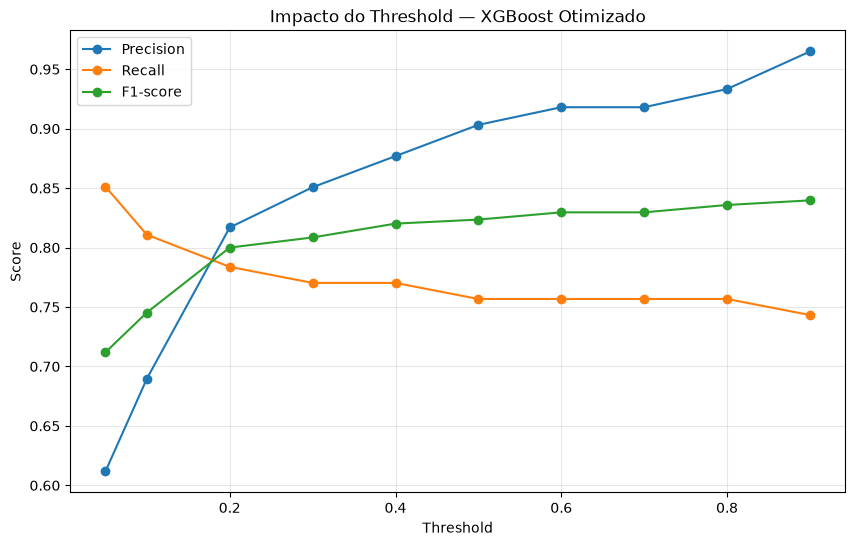

In [26]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-score"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Impacto do Threshold — XGBoost Otimizado")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [27]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

In [28]:
brier_xgb = brier_score_loss(
    y_val,
    y_proba_best_xgb
)

print(f"Brier Score do XGBoost: {brier_xgb:.6f}")

Brier Score do XGBoost: 0.000498


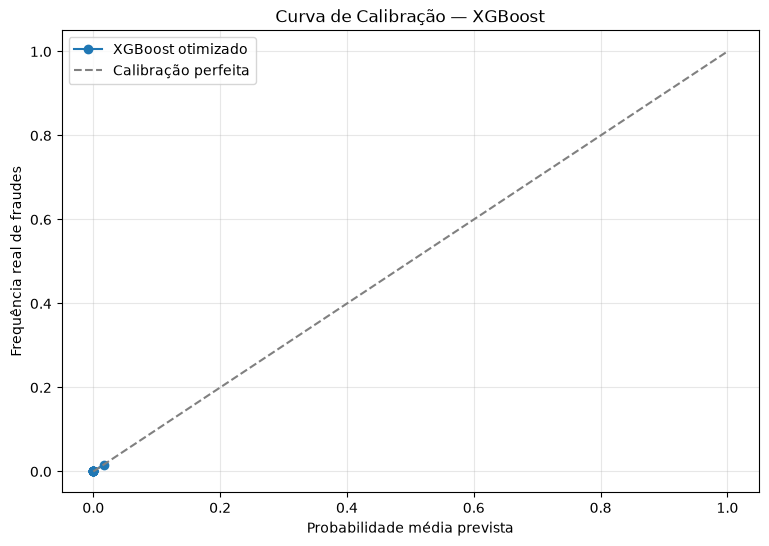

In [29]:
prob_true, prob_pred = calibration_curve(
    y_val,
    y_proba_best_xgb,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(9, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="XGBoost otimizado"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Calibração perfeita"
)

plt.xlabel("Probabilidade média prevista")
plt.ylabel("Frequência real de fraudes")

plt.title("Curva de Calibração — XGBoost")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [30]:
calibration_df = pd.DataFrame({
    "score_previsto": y_proba_best_xgb,
    "fraude_real": y_val.to_numpy()
})

calibration_df["faixa_risco"] = pd.cut(
    calibration_df["score_previsto"],
    bins=[0, 0.01, 0.05, 0.10, 0.30, 0.50, 0.70, 0.90, 1.0],
    include_lowest=True
)

calibration_summary = (
    calibration_df
    .groupby("faixa_risco", observed=True)
    .agg(
        transacoes=("fraude_real", "size"),
        fraudes_reais=("fraude_real", "sum"),
        score_medio=("score_previsto", "mean"),
        taxa_real_fraude=("fraude_real", "mean")
    )
    .reset_index()
)

display(calibration_summary.round(4))

,faixa_risco,transacoes,fraudes_reais,score_medio,taxa_real_fraude
0,"(-0.001, 0.01]",42538,10,0.0001,0.0002
1,"(0.01, 0.05]",80,1,0.0211,0.0125
2,"(0.05, 0.1]",16,3,0.0738,0.1875
3,"(0.1, 0.3]",20,3,0.1634,0.1500
4,"(0.3, 0.5]",5,1,0.3974,0.2000
5,"(0.5, 0.7]",1,0,0.5647,0.0000
6,"(0.7, 0.9]",4,1,0.8430,0.2500
7,"(0.9, 1.0]",57,55,0.9965,0.9649


In [31]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone

In [32]:
calibrated_xgb = CalibratedClassifierCV(
    estimator=clone(best_xgb),
    method="sigmoid",
    cv=3,
    n_jobs=-1
)

print(calibrated_xgb)

CalibratedClassifierCV(cv=3,
                       estimator=XGBClassifier(base_score=None, booster=None,
                                               callbacks=None,
                                               colsample_bylevel=None,
                                               colsample_bynode=None,
                                               colsample_bytree=0.8,
                                               device=None,
                                               early_stopping_rounds=None,
                                               enable_categorical=True,
                                               eval_metric='logloss',
                                               feature_types=None,
                                               feature_weights=None, gamma=None,
                                               grow_policy=None,
                                               importance_type=None,
                                               interaction_co

In [33]:
calibrated_xgb.fit(X_train, y_train)

print("XGBoost calibrado com sucesso!")

XGBoost calibrado com sucesso!


In [34]:
y_proba_calibrated = calibrated_xgb.predict_proba(X_val)[:, 1]

brier_calibrated = brier_score_loss(
    y_val,
    y_proba_calibrated
)

print("=== COMPARAÇÃO DE CALIBRAÇÃO ===")

print(f"XGBoost original:  {brier_xgb:.6f}")
print(f"XGBoost calibrado: {brier_calibrated:.6f}")

=== COMPARAÇÃO DE CALIBRAÇÃO ===
XGBoost original:  0.000498
XGBoost calibrado: 0.000484


In [35]:
y_pred_calibrated = calibrated_xgb.predict(X_val)

print("=== XGBOOST CALIBRADO ===")

print(classification_report(
    y_val,
    y_pred_calibrated,
    digits=4,
    zero_division=0
))

print(
    "Average Precision:",
    round(
        average_precision_score(
            y_val,
            y_proba_calibrated
        ),
        4
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_val,
            y_proba_calibrated
        ),
        4
    )
)

print("\nMatriz de confusão:")
print(confusion_matrix(y_val, y_pred_calibrated))

=== XGBOOST CALIBRADO ===
              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9997     42647
           1     0.9333    0.7568    0.8358        74

    accuracy                         0.9995     42721
   macro avg     0.9665    0.8783    0.9178     42721
weighted avg     0.9995    0.9995    0.9995     42721

Average Precision: 0.8354
ROC-AUC: 0.9777

Matriz de confusão:
[[42643     4]
 [   18    56]]


In [36]:
comparison_calibration = pd.DataFrame([
    {
        "Modelo": "XGBoost otimizado",
        "Average Precision": average_precision_score(
            y_val, y_proba_best_xgb
        ),
        "ROC-AUC": roc_auc_score(
            y_val, y_proba_best_xgb
        ),
        "Brier Score": brier_xgb
    },
    {
        "Modelo": "XGBoost calibrado",
        "Average Precision": average_precision_score(
            y_val, y_proba_calibrated
        ),
        "ROC-AUC": roc_auc_score(
            y_val, y_proba_calibrated
        ),
        "Brier Score": brier_calibrated
    }
])

display(comparison_calibration.round(6))

,Modelo,Average Precision,ROC-AUC,Brier Score
0,XGBoost otimizado,0.839747,0.984378,0.000498
1,XGBoost calibrado,0.835397,0.977742,0.000484
